# Exercise 30: SGD on a sum of 12 quadratics

$$f(x) = \frac{1}{n}\sum_{i=1}^n f_i(x), \qquad f_i(x) = a_i x^2 + b_i x, \qquad x \in \mathbb{R},$$

with the gradient estimator of Exercise 29: $g(x) = f_i'(x)$, $i \sim \mathrm{Uniform}\{1,\dots,n\}$.
The constants $c_i$ are taken $0$, they do not change the minimiser.

Theory (Exercise 29 + Theorem 33):
$L_i = 2a_i$, $\mu = 2\bar a$, $A = 2L_{\max}$, $C = 2\sigma_\star^2$, and for $0 < \gamma \le 1/A$
$$\mathbb{E}|x^k - x^\star|^2 \le (1-\gamma\mu)^k |x^0 - x^\star|^2 + \frac{\gamma C}{\mu}.$$

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np

## Setup
Random integer coefficients $a_i \in \{1,\dots,20\}$, $b_i \in \{-20,\dots,20\}$.

In [2]:
N = 12            # number of functions f_i
RUNS = 2000       # independent SGD runs used to estimate E|x^k - x*|^2
X0 = 10.0         # starting point
SEED = 0

rng = np.random.default_rng(SEED)
a = rng.integers(1, 21, size=N).astype(float)    # a_i in {1, ..., 20}
b = rng.integers(-20, 21, size=N).astype(float)  # b_i in {-20, ..., 20}

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

## Helper functions

In [3]:
def constants(a, b):
    """Closed-form quantities of the problem and of the AC bound."""
    x_star = -b.sum() / (2 * a.sum())
    L_max = 2 * a.max()
    mu = 2 * a.mean()
    sigma2 = np.mean((2 * a * x_star + b) ** 2)   # sigma_*^2 = 1/n sum |f_i'(x*)|^2
    return x_star, L_max, mu, 2 * L_max, 2 * sigma2


def sgd(a, b, gamma, iters, runs=RUNS, seed=SEED):
    """Run `runs` independent copies of SGD; return E|x^k - x*|^2 for k = 0..iters."""
    x_star = constants(a, b)[0]
    rng = np.random.default_rng(seed + 1)
    x = np.full(runs, X0)
    err = np.empty(iters + 1)
    err[0] = (X0 - x_star) ** 2
    for k in range(iters):
        i = rng.integers(0, len(a), size=runs)   # i ~ Uniform{1, ..., n}
        x = x - gamma * (2 * a[i] * x + b[i])    # x^{k+1} = x^k - gamma f_i'(x^k)
        err[k + 1] = np.mean((x - x_star) ** 2)
    return err


def bound(gamma, mu, C, r0, iters):
    k = np.arange(iters + 1)
    return (1 - gamma * mu) ** k * r0 + gamma * C / mu


def stationary(gamma, a, b):
    """Exact limit of E|x^k - x*|^2 for 1D quadratics (finite iff E(1 - 2 gamma a_i)^2 < 1)."""
    x_star, _, mu, _, C = constants(a, b)
    return gamma * (C / 2) / (2 * mu - 4 * gamma * np.mean(a ** 2))


def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150)
    plt.show()

## Constants of the problem

In [4]:
x_star, L_max, mu, A, C = constants(a, b)
r0 = (X0 - x_star) ** 2
print(f"a = {a.astype(int).tolist()}")
print(f"b = {b.astype(int).tolist()}")
print(f"x* = {x_star:.6f}, L_max = {L_max:g}, mu = {mu:.4f}, A = {A:g}, C = {C:.4f}")

a = [18, 13, 11, 6, 7, 1, 2, 1, 4, 17, 13, 19]
b = [0, 4, 19, 9, 5, 2, 2, 18, -9, 13, 7, -20]
x* = -0.223214, L_max = 38, mu = 18.6667, A = 76, C = 263.3080


## Experiment 1: the bound of Theorem 33
Largest stepsize allowed by the theory, $\gamma = 1/A$.

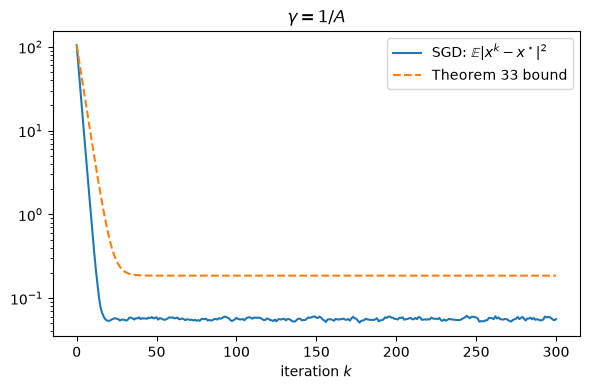

gamma = 0.01316: final error 5.611e-02, bound 1.856e-01, bound violated: False


In [8]:
iters = 300
gamma = 1 / A
err = sgd(a, b, gamma, iters)
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(err, label=r"SGD: $\mathbb{E}|x^k-x^\star|^2$")
ax.semilogy(bound(gamma, mu, C, r0, iters), "--", label="Theorem 33 bound")
ax.set_xlabel("iteration $k$")
ax.set_title(r"$\gamma = 1/A$")
ax.legend()
save(fig, "exp1_bound.png")
print(f"gamma = {gamma:.5f}: final error {err[-1]:.3e}, "
      f"bound {gamma * C / mu:.3e}, bound violated: {np.any(err > bound(gamma, mu, C, r0, iters))}")

## Experiment 2: the neighbourhood is proportional to $\gamma$
$\gamma = 1/(mA)$ for $m = 1, 4, 16, 64$ (dashed: $\gamma C/\mu$).

gamma = 1/(1A): plateau 5.671e-02, radius gamma*C/mu 1.856e-01, ratio 0.306, exact limit 5.665e-02
gamma = 1/(4A): plateau 1.219e-02, radius gamma*C/mu 4.640e-02, ratio 0.263, exact limit 1.215e-02


gamma = 1/(16A): plateau 2.940e-03, radius gamma*C/mu 1.160e-02, ratio 0.253, exact limit 2.933e-03


gamma = 1/(64A): plateau 7.156e-04, radius gamma*C/mu 2.900e-03, ratio 0.247, exact limit 7.271e-04


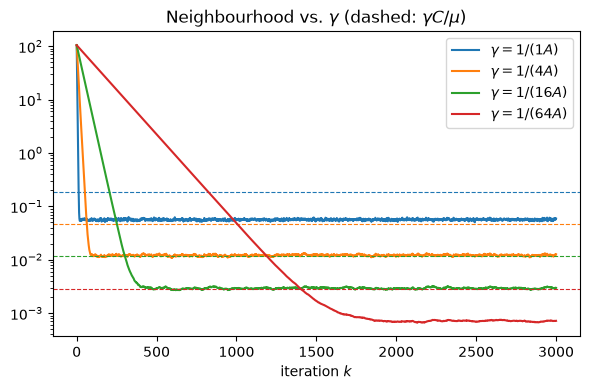

In [6]:
iters = 3000
fig, ax = plt.subplots(figsize=(6, 4))
for m in [1, 4, 16, 64]:
    gamma = 1 / (m * A)
    err = sgd(a, b, gamma, iters)
    line, = ax.semilogy(err, label=fr"$\gamma = 1/({m}A)$")
    ax.axhline(gamma * C / mu, ls="--", color=line.get_color(), lw=0.8)
    plateau = err[-500:].mean()
    print(f"gamma = 1/({m}A): plateau {plateau:.3e}, "
          f"radius gamma*C/mu {gamma * C / mu:.3e}, ratio {plateau / (gamma * C / mu):.3f}, "
          f"exact limit {stationary(gamma, a, b):.3e}")
ax.set_xlabel("iteration $k$")
ax.set_title(r"Neighbourhood vs. $\gamma$ (dashed: $\gamma C/\mu$)")
ax.legend()
save(fig, "exp2_neighbourhood.png")